#### Isolation forest is one the more advanced outlier detection/removal algorithms

In [1]:
# can process the whole dataset 
# and compares variables to each other instead
# of focusing on outliers on a single variable
from sklearn.ensemble import IsolationForest
import pandas as pd

# adjust the contamination rate as you see fit
# for example, if you expect 5% of the data to be outliers
# you can use 0.05 etc. 

# basically, this is how aggressive Isolation Forest will be
# increase if you think you need to detect more outliers
# decrease if you need less outliers
iso = IsolationForest(contamination=0.05) 
df = pd.read_csv("../heart.csv")



In [2]:
# this just converts the value of column to 0 or 1
# factorize in pandas works too, but only one column at a time
from sklearn.preprocessing import LabelEncoder
variables = ['ExerciseAngina']
encoder = LabelEncoder()
df[variables] = df[variables].apply(encoder.fit_transform)

In [3]:
cut_mapper = {'Down': 1, 'Flat': 2,'Up': 3}
df['ST_Slope'] = df['ST_Slope'].map(cut_mapper)

In [4]:
# this makes multiple columns with the variable (Separate for yes/no)
from sklearn.preprocessing import OneHotEncoder
variables = ['Sex', 'ChestPainType', 'RestingECG']

# use encoder
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_encoded = encoder.fit_transform(df[variables]).astype(int)
df = pd.concat([df,one_hot_encoded],axis=1).drop(columns=variables)

In [5]:
# REMEMBER! Isolation Forest is a machine learning algorithm
# => ALL VARIABLES HAVE TO BE NUMERIC AT THIS POINT

# fit isolation forest
y_pred = iso.fit_predict(df)

# separate outliers and inliers into separate DataFrames
outliers = df[y_pred != 1]
inliers = df[y_pred == 1]

print(f"Inliers: {len(inliers)}")
print(f"Outliers: {len(outliers)}")

Inliers: 872
Outliers: 46


In [6]:
df

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
0,40,140,289,0,172,0,0.0,3,0,0,1,0,1,0,0,0,1,0
1,49,160,180,0,156,0,1.0,2,1,1,0,0,0,1,0,0,1,0
2,37,130,283,0,98,0,0.0,3,0,0,1,0,1,0,0,0,0,1
3,48,138,214,0,108,1,1.5,2,1,1,0,1,0,0,0,0,1,0
4,54,150,195,0,122,0,0.0,3,0,0,1,0,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,0,1.2,2,1,0,1,0,0,0,1,0,1,0
914,68,144,193,1,141,0,3.4,2,1,0,1,1,0,0,0,0,1,0
915,57,130,131,0,115,1,1.2,2,1,0,1,1,0,0,0,0,1,0
916,57,130,236,0,174,0,0.0,2,1,1,0,0,1,0,0,1,0,0


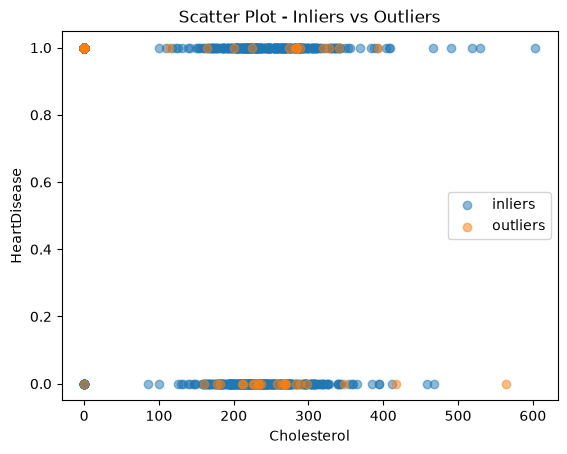

In [7]:
import matplotlib.pyplot as plt

# change the variable if you want to inspect this from other point of views
variable = "Cholesterol"
target = "HeartDisease"
# if you want to reduce the number of points visualized
# sample a small amount of points, for example 300-500
# inliers_sample = inliers.sample(3000)
# outliers_sample = outliers.sample(100)
inliers_sample = inliers
outliers_sample = outliers

plt.scatter(inliers_sample[variable], inliers_sample[target], label="inliers", alpha=0.5)
plt.scatter(outliers_sample[variable], outliers_sample[target], label="outliers", alpha=0.5)

plt.xlabel(variable)
plt.ylabel(target)

plt.title("Scatter Plot - Inliers vs Outliers")
plt.legend()
plt.show()

In [8]:
outliers

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
118,35,120,160,0,185,0,0.0,3,0,1,0,0,0,0,1,0,0,1
123,58,180,393,0,110,1,1.0,2,1,1,0,0,1,0,0,0,1,0
215,30,170,237,0,170,0,0.0,3,0,1,0,0,0,0,1,0,0,1
278,57,180,347,0,126,1,0.8,2,0,1,0,1,0,0,0,0,0,1
294,32,95,0,1,127,0,0.7,3,1,0,1,0,0,0,1,0,1,0
303,62,120,0,1,123,1,1.7,1,1,1,0,1,0,0,0,0,0,1
315,74,145,0,1,123,0,1.3,3,1,0,1,0,1,0,0,0,0,1
322,38,105,0,1,166,0,2.8,3,1,1,0,1,0,0,0,0,1,0
335,62,120,0,1,134,0,-0.8,2,1,0,1,0,0,0,1,1,0,0
375,73,160,0,0,121,0,0.0,3,1,1,0,0,0,1,0,0,0,1


#### Another popular alternative: Elliptic Envelope

In [9]:
from sklearn.covariance import EllipticEnvelope

# contamination, same thing as in isolation
ee = EllipticEnvelope(contamination=0.05)
df = pd.read_csv("../heart.csv")

# contamination, same thing as in isolation
variable = "Cholesterol"
target = "HeartDisease"

# handle these better with your own dataset, here we are simply dropping these
df = df.dropna()



In [10]:
# this just converts the value of column to 0 or 1
# factorize in pandas works too, but only one column at a time
from sklearn.preprocessing import LabelEncoder
variables = ['ExerciseAngina']
encoder = LabelEncoder()
df[variables] = df[variables].apply(encoder.fit_transform)

In [11]:
cut_mapper = {'Down': 1, 'Flat': 2,'Up': 3}
df['ST_Slope'] = df['ST_Slope'].map(cut_mapper)

In [12]:
# this makes multiple columns with the variable (Separate for yes/no)
from sklearn.preprocessing import OneHotEncoder
variables = ['Sex', 'ChestPainType', 'RestingECG']

# use encoder
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_encoded = encoder.fit_transform(df[variables]).astype(int)
df = pd.concat([df,one_hot_encoded],axis=1).drop(columns=variables)

In [13]:
y_pred = ee.fit_predict(df)
outliers = df[y_pred != 1]
inliers = df[y_pred == 1]

# Add outlier
df["outlier"] = y_pred == -1

c:\Users\Gayani\Advanced Data Analytics\AdvancedDataAnalytics\.venv\Lib\site-packages\sklearn\covariance\_robust_covariance.py:793: UserWarning: The covariance matrix associated to your dataset is not full rank
  warnings.warn(


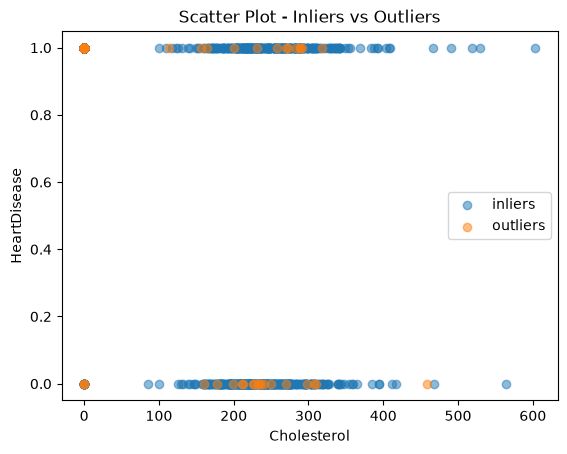

In [14]:
import matplotlib.pyplot as plt

variable = "Cholesterol"
target = "HeartDisease"

# if you want to reduce the number of points visualized
# sample a small amount of points, for example 300-500
# inliers_sample = inliers.sample(3000)
# outliers_sample = outliers.sample(100)
inliers_sample = inliers
outliers_sample = outliers

plt.scatter(inliers_sample[variable], inliers_sample[target], label="inliers", alpha=0.5)
plt.scatter(outliers_sample[variable], outliers_sample[target], label="outliers", alpha=0.5)

plt.xlabel(variable)
plt.ylabel(target)

plt.title("Scatter Plot - Inliers vs Outliers")
plt.legend()
plt.show()